## 1. Project introduction

This notebook builds a reproducible binary classifier from the official UCI Cleveland heart disease dataset. It is an educational demonstration, not a medical device.

## 2. Problem statement

Given 13 recorded patient measurements and categories, predict whether the Cleveland target `num` is zero or greater than zero.

## 3. Objectives

Inspect and clean the source data; explore distributions; compare four algorithms with stratified cross-validation; tune them on training data; evaluate one selected pipeline on untouched test data; export the full pipeline for Flask.

## 4. Import required libraries

Use a fixed seed throughout. All saved paths are relative to the project folder.

In [1]:
from pathlib import Path
import json
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "dataset").exists() else Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "dataset" / "heart_disease.csv"
MODEL_PATH = PROJECT_ROOT / "models" / "best_heart_model.pkl"
METADATA_PATH = PROJECT_ROOT / "models" / "model_metadata.json"
FEATURES = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg", "thalach", "exang", "oldpeak", "slope", "ca", "thal"]
NUMERIC = ["age", "trestbps", "chol", "thalach", "oldpeak"]
CATEGORICAL = [name for name in FEATURES if name not in NUMERIC]
print("Project root:", PROJECT_ROOT.resolve())

Project root: C:\Users\bhush\Projects\aiml\Heart-Disease-Prediction


## 5. Download and load the dataset

Fetch UCI repository dataset 45 when the local CSV is absent. A fresh checkout can rerun this cell; a downloaded CSV makes subsequent runs offline capable. The CSV preserves the original `num` target and missing cells.

In [2]:
if not DATA_PATH.exists():
    try:
        source = fetch_ucirepo(id=45)
        raw = source.data.features.join(source.data.targets.rename(columns={source.data.targets.columns[0]: "num"}))
        DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
        raw.to_csv(DATA_PATH, index=False)
    except Exception as exc:
        raise RuntimeError("Could not download UCI Heart Disease dataset 45. Download the official Cleveland data from https://archive.ics.uci.edu/dataset/45/heart+disease and save a 13-feature plus num CSV at dataset/heart_disease.csv.") from exc
raw = pd.read_csv(DATA_PATH, na_values=["?", "", "NA", "N/A"])
assert list(raw.columns) == FEATURES + ["num"], "Unexpected source columns"
print("Source rows, columns:", raw.shape)
display(raw.head())

Source rows, columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 6. Dataset description and feature information

The original target is 0–4; values 1–4 indicate disease presence. UCI defines `cp` as 1 typical angina, 2 atypical angina, 3 non-anginal pain, 4 asymptomatic; `restecg` as 0 normal, 1 ST-T abnormality, 2 left ventricular hypertrophy; `slope` as 1 upsloping, 2 flat, 3 downsloping; `ca` as 0–3 vessels; and `thal` as 3 normal, 6 fixed defect, 7 reversible defect. [UCI source](https://archive.ics.uci.edu/dataset/45/heart+disease).

In [3]:
feature_info = pd.DataFrame({"Feature": FEATURES,
    "Kind": ["Numeric" if x in NUMERIC else "Categorical" for x in FEATURES],
    "Description": ["Age (years)", "Sex", "Chest pain type", "Resting blood pressure (mm Hg)",
                    "Serum cholesterol (mg/dl)", "Fasting blood sugar >120 mg/dl", "Resting ECG",
                    "Maximum heart rate", "Exercise-induced angina", "ST depression", "ST slope",
                    "Major vessels colored by fluoroscopy", "Thal result"]})
display(feature_info)

,Feature,Kind,Description
0,age,Numeric,Age (years)
1,sex,Categorical,Sex
2,cp,Categorical,Chest pain type
3,trestbps,Numeric,Resting blood pressure (mm Hg)
4,chol,Numeric,Serum cholesterol (mg/dl)
5,fbs,Categorical,Fasting blood sugar >120 mg/dl
6,restecg,Categorical,Resting ECG
7,thalach,Numeric,Maximum heart rate
8,exang,Categorical,Exercise-induced angina
9,oldpeak,Numeric,ST depression


## 7. Dataset shape and column information

Check the raw source before changing any values.

In [4]:
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
raw.info()

Shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


## 8. Data types and statistical summary

Some source category columns may appear numeric; they remain categorical for modeling.

In [5]:
display(raw.dtypes.to_frame("dtype"))
display(raw.describe(include="all").T)

,dtype
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64


,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


## 9. Missing value analysis

Count missing cells, including `?` parsed as missing. Imputation will be fit on each training fold only.

In [6]:
display(raw.isna().sum().to_frame("missing_count"))
print("Rows with any missing feature:", raw[FEATURES].isna().any(axis=1).sum())

,missing_count
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


Rows with any missing feature: 6


## 10. Duplicate record detection

Exact duplicate rows are checked, including the original target.

In [7]:
print("Exact duplicate rows:", raw.duplicated().sum())

Exact duplicate rows: 0


## 11. Data cleaning

Convert values to numeric, reject invalid targets, remove exact duplicate records, and keep missing feature values for the pipeline's imputers. No missing value is filled using the full dataset.

In [8]:
clean = raw.copy()
for column in FEATURES + ["num"]:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")
clean = clean.dropna(subset=["num"]).drop_duplicates().reset_index(drop=True)
if not clean["num"].isin([0, 1, 2, 3, 4]).all():
    raise ValueError("Unexpected target values")
clean["target"] = (clean["num"] > 0).astype(int)
print("Cleaned shape:", clean.shape)
display(clean[FEATURES + ["target"]].head())

Cleaned shape: (303, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


## 12. Target variable distribution

The target is binary after mapping 0 to absent and 1–4 to present.

target
Absent     164
Present    139
Name: count, dtype: int64

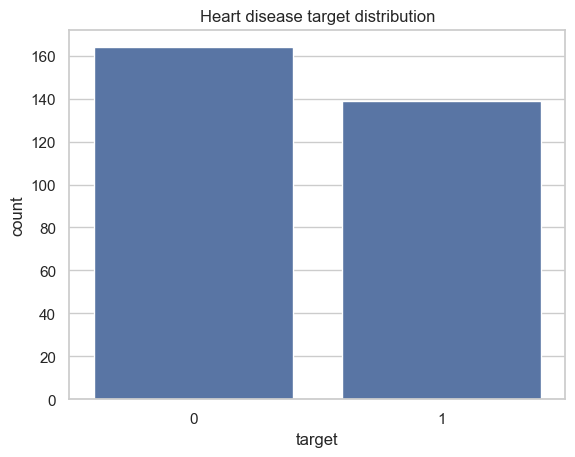

In [9]:
display(clean["target"].value_counts().sort_index().rename(index={0:"Absent", 1:"Present"}))
sns.countplot(data=clean, x="target")
plt.title("Heart disease target distribution")
plt.show()

## 13. Exploratory Data Analysis

Explore descriptive relationships only; these plots do not select the model.

In [10]:
display(clean.groupby("target")[NUMERIC].median().round(1))

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0,52.0,130.0,234.5,161.0,0.2
1,58.0,130.0,249.0,142.0,1.4


## 14. Univariate analysis

Counts of chest-pain categories show the source distribution.

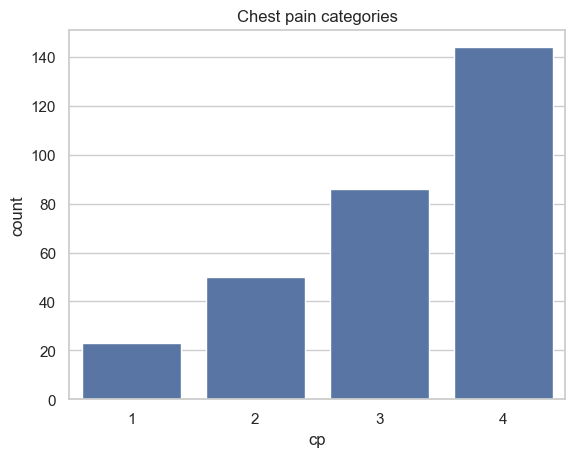

In [11]:
sns.countplot(data=clean, x="cp")
plt.title("Chest pain categories")
plt.show()

## 15. Bivariate analysis

Compare chest-pain categories and the target without inferring causation.

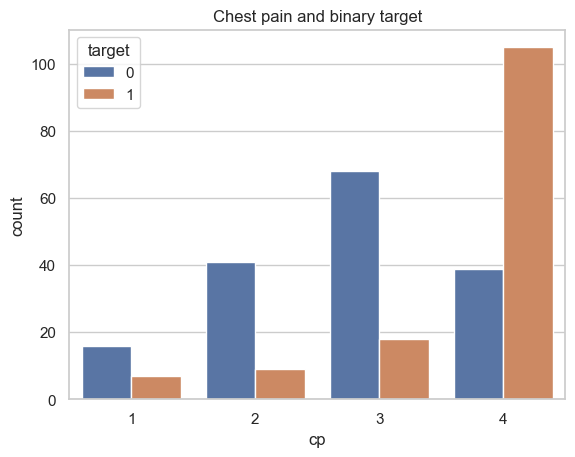

In [12]:
sns.countplot(data=clean, x="cp", hue="target")
plt.title("Chest pain and binary target")
plt.show()

## 16. Histograms

Histograms reveal ranges and skew in numerical measurements.

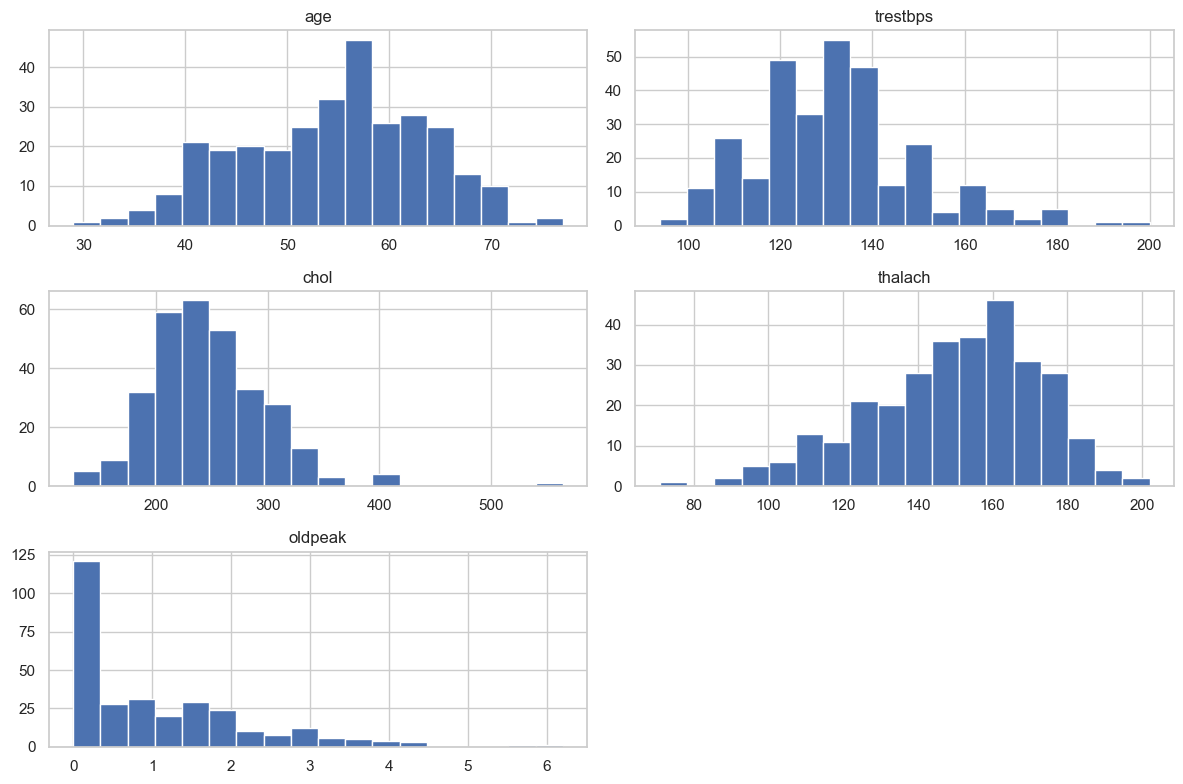

In [13]:
clean[NUMERIC].hist(figsize=(12, 8), bins=18)
plt.tight_layout()
plt.show()

## 17. Boxplots

Boxplots show spread and possible outliers; outliers are not automatically removed.

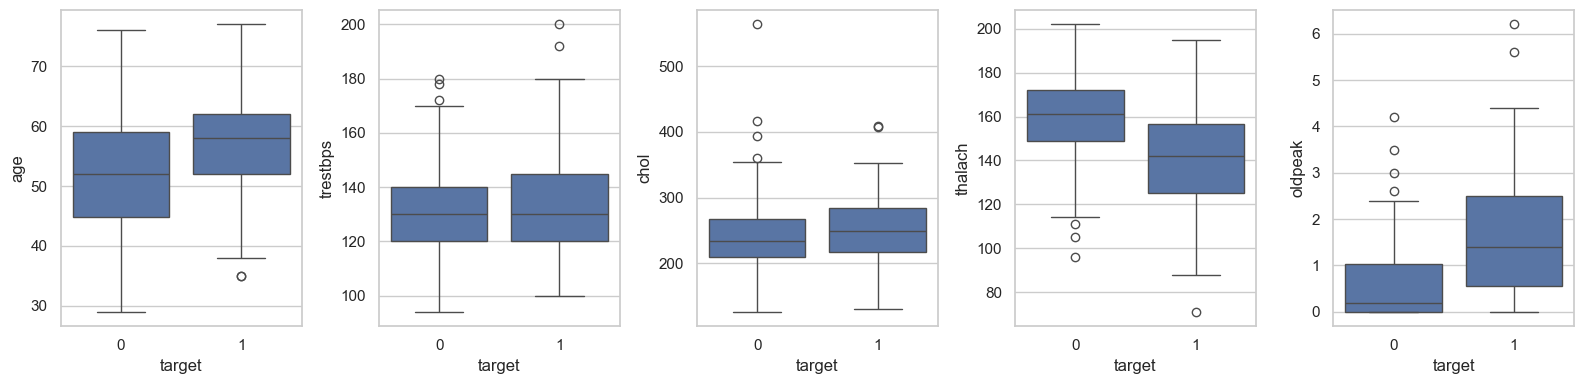

In [14]:
fig, axes = plt.subplots(1, len(NUMERIC), figsize=(16, 4))
for ax, feature in zip(axes, NUMERIC):
    sns.boxplot(data=clean, x="target", y=feature, ax=ax)
plt.tight_layout()
plt.show()

## 18. Correlation heatmap

This is a descriptive Pearson correlation across encoded source numbers, not a causal analysis of categorical codes.

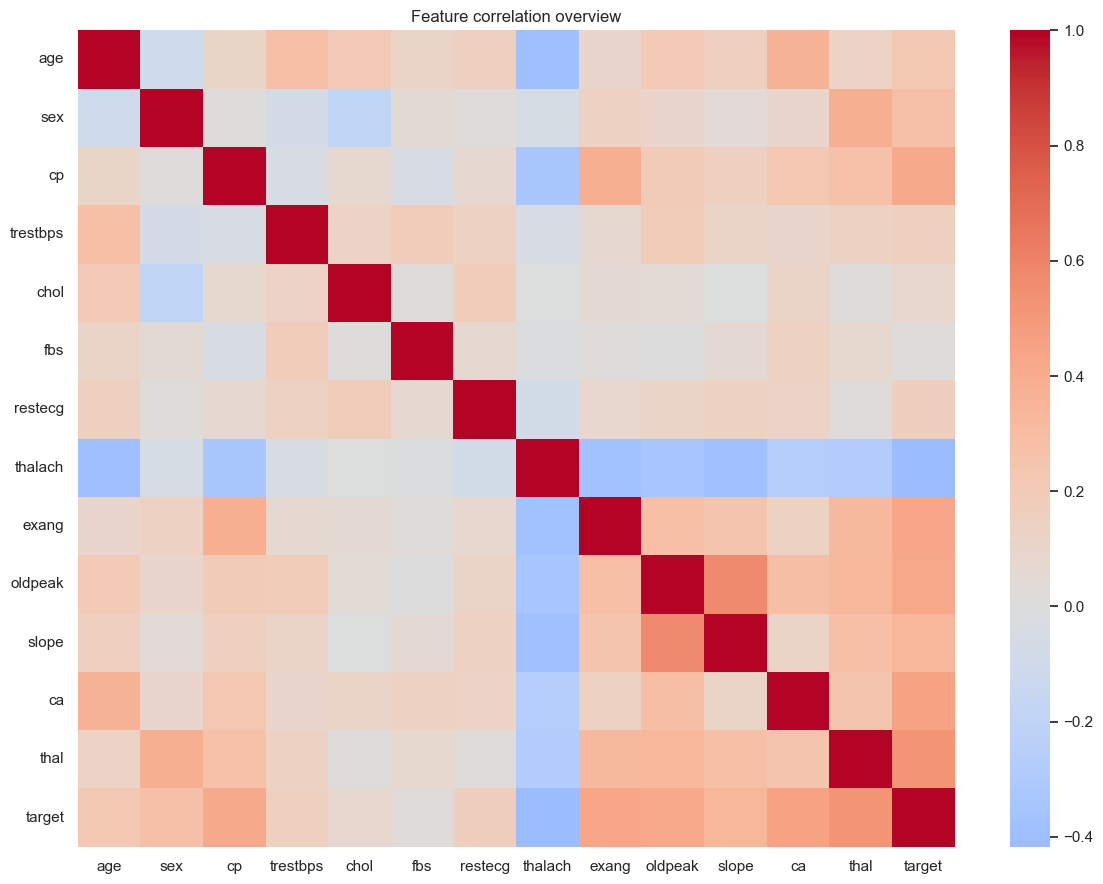

In [15]:
plt.figure(figsize=(12, 9))
sns.heatmap(clean[FEATURES + ["target"]].corr(), cmap="coolwarm", center=0)
plt.title("Feature correlation overview")
plt.tight_layout()
plt.show()

## 19. Feature distribution analysis

The maximum heart rate distribution differs across the two target groups in this sample.

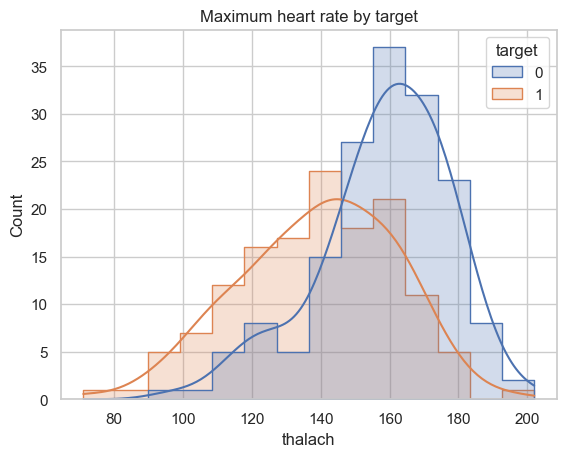

In [16]:
sns.histplot(data=clean, x="thalach", hue="target", kde=True, element="step")
plt.title("Maximum heart rate by target")
plt.show()

## 20. Data preprocessing

A `ColumnTransformer` handles numeric and categorical columns inside every estimator pipeline.

In [17]:
numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                             ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("numeric", numeric_pipe, NUMERIC),
                                  ("categorical", categorical_pipe, CATEGORICAL)])
print(preprocessor)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['sex', 'cp', 'fbs', 'restecg', 'exang',
                                  'slope', 'ca', 'thal'])])


## 21. Categorical feature encoding

One-hot encoding prevents category codes such as chest-pain type from implying a numeric distance.

In [18]:
print("Categorical columns:", CATEGORICAL)
for name in CATEGORICAL:
    print(name, sorted(clean[name].dropna().unique().tolist()))

Categorical columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
sex [0, 1]
cp [1, 2, 3, 4]
fbs [0, 1]
restecg [0, 1, 2]
exang [0, 1]
slope [1, 2, 3]
ca [0.0, 1.0, 2.0, 3.0]
thal [3.0, 6.0, 7.0]


## 22. Numerical feature scaling

Standardization helps Logistic Regression and KNN. Tree models can also use the same complete pipeline for a consistent interface.

In [19]:
print("Scaled numerical columns:", NUMERIC)

Scaled numerical columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']


## 23. Missing value imputation

Numeric medians and categorical modes are learned only when a pipeline is fit to training data or a training fold.

In [20]:
print("Remaining source missing values:", clean[FEATURES].isna().sum().sum())

Remaining source missing values: 6


## 24. Train-test split (80:20, stratified)

The test set is held aside before fitting or selecting a model.

In [21]:
X = clean[FEATURES].copy()
y = clean["target"].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train target counts:", y_train.value_counts().to_dict())
print("Test target counts:", y_test.value_counts().to_dict())

Train: (242, 13) Test: (61, 13)
Train target counts: {0: 131, 1: 111}
Test target counts: {0: 33, 1: 28}


## 25. Logistic Regression implementation

A linear baseline with regularization and enough iterations for convergence.

In [22]:
models = {"Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)}
print(models["Logistic Regression"])

LogisticRegression(max_iter=2000, random_state=42)


## 26. K-Nearest Neighbors implementation

KNN classifies by nearby observations in preprocessed feature space.

In [23]:
models["KNN"] = KNeighborsClassifier()
print(models["KNN"])

KNeighborsClassifier()


## 27. Decision Tree implementation

Depth limits will be tuned to control overfitting.

In [24]:
models["Decision Tree"] = DecisionTreeClassifier(random_state=RANDOM_STATE)
print(models["Decision Tree"])

DecisionTreeClassifier(random_state=42)


## 28. Random Forest implementation

An ensemble of decision trees provides another nonlinear candidate.

In [25]:
models["Random Forest"] = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1)
pipelines = {name: Pipeline([("preprocessor", preprocessor), ("classifier", estimator)])
             for name, estimator in models.items()}
print(list(pipelines))

['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest']


## 29. Model evaluation

Baseline comparisons use only training folds. AUC uses predicted probabilities. These are out-of-fold estimates, not held-out test results.

In [26]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
oof = {}
for name, pipe in pipelines.items():
    probabilities = cross_val_predict(pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    oof[name] = {"probabilities": probabilities, "predictions": predictions}
print("Out-of-fold predictions generated on training data only.")

Out-of-fold predictions generated on training data only.


## 30. Accuracy

Accuracy is the fraction of correct predictions, but can hide class imbalance.

In [27]:
print({name: round(accuracy_score(y_train, values["predictions"]), 3) for name, values in oof.items()})

{'Logistic Regression': 0.847, 'KNN': 0.822, 'Decision Tree': 0.698, 'Random Forest': 0.818}


## 31. Precision

Precision is the fraction of predicted positives that are positive in the data.

In [28]:
print({name: round(precision_score(y_train, values["predictions"], zero_division=0), 3) for name, values in oof.items()})

{'Logistic Regression': 0.87, 'KNN': 0.821, 'Decision Tree': 0.667, 'Random Forest': 0.807}


## 32. Recall

Recall is the fraction of actual positives that the model detects.

In [29]:
print({name: round(recall_score(y_train, values["predictions"]), 3) for name, values in oof.items()})

{'Logistic Regression': 0.784, 'KNN': 0.784, 'Decision Tree': 0.685, 'Random Forest': 0.793}


## 33. F1-score

F1 balances precision and recall.

In [30]:
print({name: round(f1_score(y_train, values["predictions"]), 3) for name, values in oof.items()})

{'Logistic Regression': 0.825, 'KNN': 0.802, 'Decision Tree': 0.676, 'Random Forest': 0.8}


## 34. ROC-AUC

ROC-AUC summarizes ranking across probability thresholds.

In [31]:
print({name: round(roc_auc_score(y_train, values["probabilities"]), 3) for name, values in oof.items()})

{'Logistic Regression': 0.905, 'KNN': 0.868, 'Decision Tree': 0.697, 'Random Forest': 0.893}


## 35. Confusion matrices for all models

Rows are actual classes; columns are predicted classes. All panels use out-of-fold training predictions.

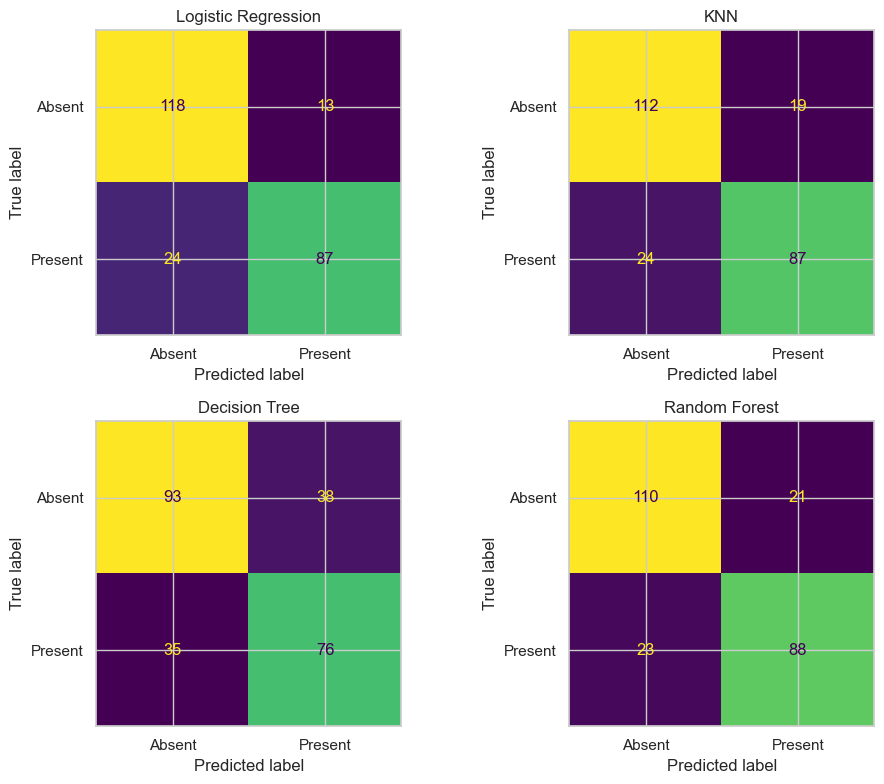

In [32]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, (name, values) in zip(axes.flat, oof.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_train, values["predictions"]),
                           display_labels=["Absent", "Present"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 36. ROC curves

The curves use out-of-fold training probabilities.

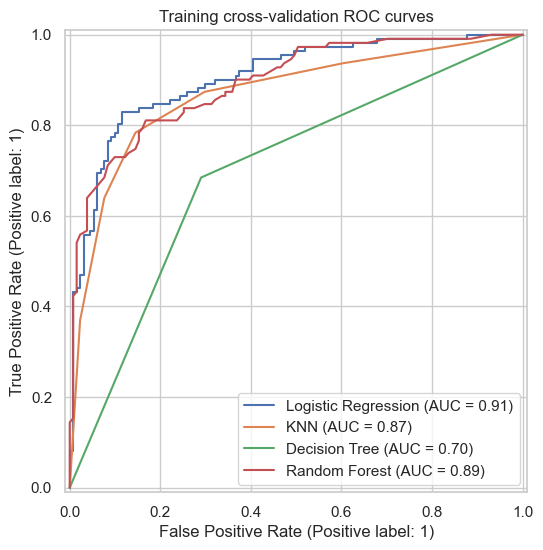

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, values in oof.items():
    RocCurveDisplay.from_predictions(y_train, values["probabilities"], name=name, ax=ax)
plt.title("Training cross-validation ROC curves")
plt.show()

## 37. Model comparison table

These baseline metrics all come from the same training-only out-of-fold predictions.

In [34]:
comparison = pd.DataFrame([
    {"Model": name,
     "Accuracy": accuracy_score(y_train, values["predictions"]),
     "Precision": precision_score(y_train, values["predictions"], zero_division=0),
     "Recall": recall_score(y_train, values["predictions"]),
     "F1": f1_score(y_train, values["predictions"]),
     "ROC-AUC": roc_auc_score(y_train, values["probabilities"])}
    for name, values in oof.items()]).sort_values("ROC-AUC", ascending=False)
display(comparison.round(3))

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.847,0.870,0.784,0.825,0.905
3,Random Forest,0.818,0.807,0.793,0.800,0.893
1,KNN,0.822,0.821,0.784,0.802,0.868
2,Decision Tree,0.698,0.667,0.685,0.676,0.697


## 38. Model performance visualization

Compare multiple metrics rather than declaring a winner by accuracy alone.

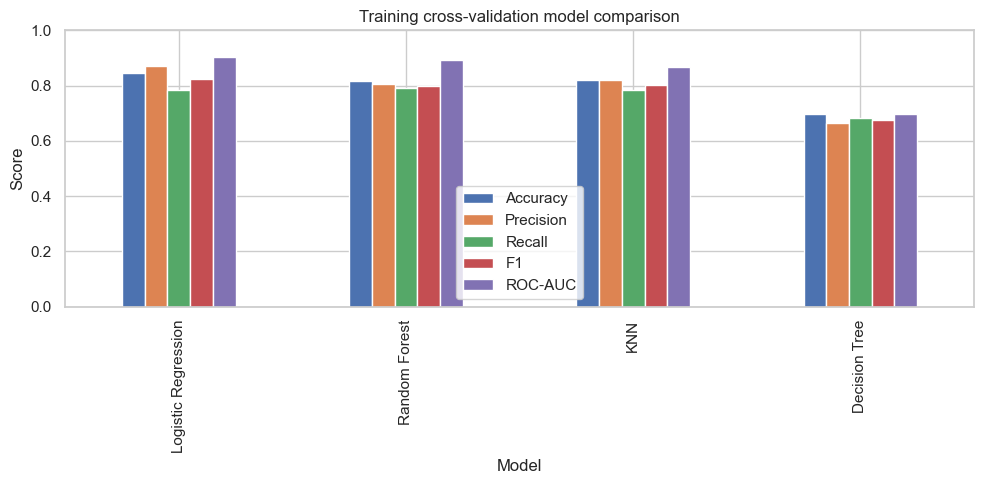

In [35]:
comparison.set_index("Model")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot.bar(
    figsize=(10, 5), ylim=(0, 1))
plt.title("Training cross-validation model comparison")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## 39. Stratified cross-validation

Five stratified folds preserve class proportions. Each fold refits preprocessing on its own training portion.

In [36]:
cv_rows = []
for name, pipe in pipelines.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv,
                            scoring={"accuracy": "accuracy", "precision": "precision",
                                     "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"})
    cv_rows.append({"Model": name, **{metric: np.mean(scores["test_" + metric])
                                       for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]}})
cv_table = pd.DataFrame(cv_rows).sort_values("roc_auc", ascending=False)
display(cv_table.round(3))

,Model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.847,0.877,0.783,0.825,0.902
3,Random Forest,0.818,0.817,0.783,0.795,0.897
1,KNN,0.822,0.823,0.783,0.799,0.871
2,Decision Tree,0.698,0.678,0.684,0.677,0.697


## 40. Hyperparameter tuning using GridSearchCV

Small grids keep execution practical. Tuning refits the complete pipeline inside five stratified training folds. Primary selection metric is mean CV ROC-AUC; F1 and recall are reported as context.

In [37]:
grids = {
    "Logistic Regression": {"classifier__C": [0.1, 1.0, 10.0]},
    "KNN": {"classifier__n_neighbors": [3, 5, 9], "classifier__weights": ["uniform", "distance"]},
    "Decision Tree": {"classifier__max_depth": [3, 5, None], "classifier__min_samples_leaf": [1, 4]},
    "Random Forest": {"classifier__n_estimators": [100, 200], "classifier__max_depth": [5, None],
                      "classifier__min_samples_leaf": [1, 3]}}
searches = {}
tuned_rows = []
for name, pipe in pipelines.items():
    search = GridSearchCV(pipe, grids[name], cv=cv, scoring={"roc_auc": "roc_auc", "f1": "f1", "recall": "recall"},
                          refit="roc_auc", n_jobs=1, error_score="raise")
    search.fit(X_train, y_train)
    searches[name] = search
    best = search.best_index_
    tuned_rows.append({"Model": name, "CV ROC-AUC": search.cv_results_["mean_test_roc_auc"][best],
                       "CV F1": search.cv_results_["mean_test_f1"][best],
                       "CV Recall": search.cv_results_["mean_test_recall"][best],
                       "Best parameters": search.best_params_})
tuned_table = pd.DataFrame(tuned_rows).sort_values(["CV ROC-AUC", "CV F1"], ascending=False)
display(tuned_table.round(3))

,Model,CV ROC-AUC,CV F1,CV Recall,Best parameters
0,Logistic Regression,0.902,0.825,0.783,{'classifier__C': 1.0}
3,Random Forest,0.901,0.781,0.764,"{'classifier__max_depth': 5, 'classifier__min_..."
1,KNN,0.881,0.799,0.783,"{'classifier__n_neighbors': 5, 'classifier__we..."
2,Decision Tree,0.836,0.743,0.729,"{'classifier__max_depth': 3, 'classifier__min_..."


## 41. Final model selection

Select the highest mean tuned training CV ROC-AUC, using F1 as a tie breaker. The test set has not influenced selection. This scoring rule values ranking while showing recall and F1 alongside it.

In [38]:
selected_name = str(tuned_table.iloc[0]["Model"])
final_pipeline = searches[selected_name].best_estimator_
print("Selected model:", selected_name)
print("Best training CV ROC-AUC:", round(searches[selected_name].best_score_, 3))
print("Parameters:", searches[selected_name].best_params_)

Selected model: Logistic Regression
Best training CV ROC-AUC: 0.902
Parameters: {'classifier__C': 1.0}


## 42. Final test-set evaluation

Evaluate the chosen, already refit pipeline once on the untouched 20% holdout. This small test set has uncertainty and is not clinical validation.

accuracy     0.885
precision    0.839
recall       0.929
f1           0.881
roc_auc      0.966
Name: Held-out test score, dtype: float64

              precision    recall  f1-score   support

      Absent       0.93      0.85      0.89        33
     Present       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



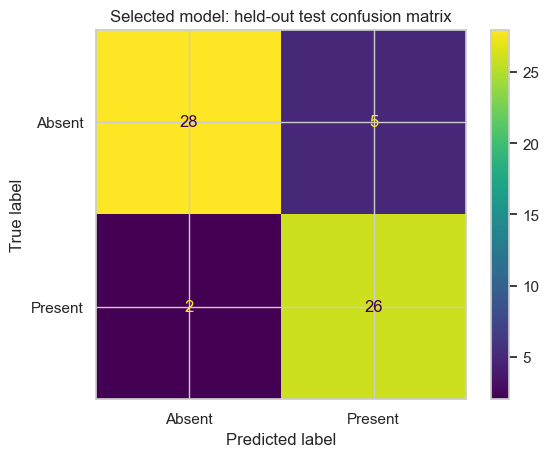

In [39]:
test_pred = final_pipeline.predict(X_test)
test_proba = final_pipeline.predict_proba(X_test)[:, 1]
test_metrics = {"accuracy": accuracy_score(y_test, test_pred),
                "precision": precision_score(y_test, test_pred, zero_division=0),
                "recall": recall_score(y_test, test_pred),
                "f1": f1_score(y_test, test_pred),
                "roc_auc": roc_auc_score(y_test, test_proba)}
display(pd.Series(test_metrics, name="Held-out test score").round(3))
print(classification_report(y_test, test_pred, target_names=["Absent", "Present"]))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["Absent", "Present"])
plt.title("Selected model: held-out test confusion matrix")
plt.show()

## 43. Feature importance where applicable

Tree importance or linear coefficient magnitude is descriptive, affected by one-hot encoding and correlated features, and is not a clinical explanation.

,importance
categorical__ca_0.0,1.498641
categorical__cp_4.0,1.030561
categorical__thal_7.0,0.818491
categorical__sex_0.0,0.700836
categorical__sex_1.0,0.690353
categorical__ca_2.0,0.642171
categorical__cp_1.0,0.619176
categorical__slope_2.0,0.603427
categorical__cp_3.0,0.574766
categorical__thal_3.0,0.540243


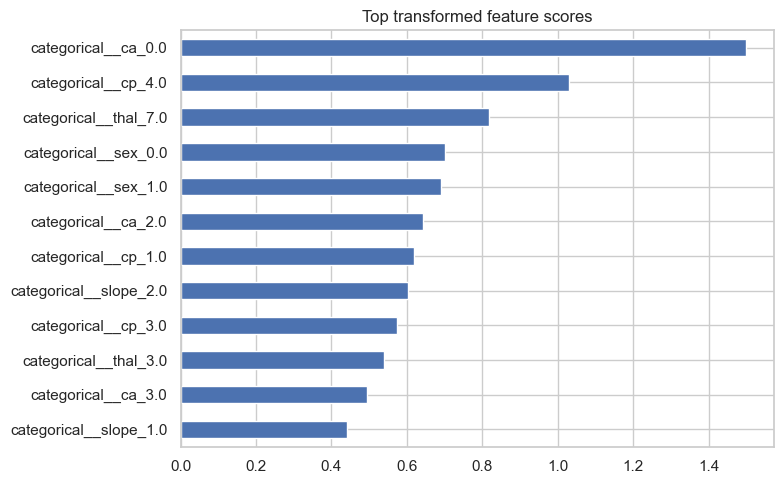

In [40]:
classifier = final_pipeline.named_steps["classifier"]
encoded_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()
if hasattr(classifier, "feature_importances_"):
    importance = classifier.feature_importances_
elif hasattr(classifier, "coef_"):
    importance = np.abs(classifier.coef_[0])
else:
    importance = None
if importance is not None:
    ranked = pd.Series(importance, index=encoded_names).sort_values(ascending=False).head(12)
    display(ranked.to_frame("importance"))
    ranked.sort_values().plot.barh(figsize=(8, 5), title="Top transformed feature scores")
    plt.tight_layout()
    plt.show()
else:
    print("Native feature importance is not available for", selected_name)

## 44. Save the best complete preprocessing and classification pipeline using Joblib

The artifact includes imputers, scaling, encoding, and the fitted classifier. Metadata records the exact feature contract and observed source ranges. Load Joblib files only from trusted sources.

In [41]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(final_pipeline, MODEL_PATH)
metadata = {
    "dataset_source": "https://archive.ics.uci.edu/dataset/45/heart+disease",
    "feature_names": FEATURES,
    "expected_feature_types": {name: ("number" if name in NUMERIC else "category") for name in FEATURES},
    "categorical_values": {name: [int(v) for v in sorted(clean[name].dropna().unique())] for name in CATEGORICAL},
    "numeric_ranges": {name: {"min": float(clean[name].min()), "max": float(clean[name].max())} for name in NUMERIC},
    "target_mapping": {"0": "No heart disease", "1": "Heart disease present (original values 1–4)"},
    "selected_model_name": selected_name,
    "selection_metric": "5-fold stratified training CV ROC-AUC",
    "selection_cv_roc_auc": float(searches[selected_name].best_score_),
    "test_metrics": {key: float(value) for key, value in test_metrics.items()},
    "model_comparison": [{"model": str(row["Model"]), **{metric: float(row[metric]) for metric in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]}} for _, row in comparison.iterrows()],
    "tuned_comparison": [{"model": str(row["Model"]), **{metric: float(row[metric]) for metric in ["CV ROC-AUC", "CV F1", "CV Recall"]}} for _, row in tuned_table.iterrows()],
    "source_rows": int(len(raw)), "clean_rows": int(len(clean)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test))}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved:", MODEL_PATH, METADATA_PATH)

Saved: C:\Users\bhush\Projects\aiml\Heart-Disease-Prediction\models\best_heart_model.pkl C:\Users\bhush\Projects\aiml\Heart-Disease-Prediction\models\model_metadata.json


## 45. Test predictions using new sample inputs

Use a complete example input with the same 13 names as Flask. Its probability is a model output, not a clinically calibrated risk estimate.

In [42]:
sample = pd.DataFrame([{"age": 54, "sex": 1, "cp": 4, "trestbps": 130, "chol": 246,
                        "fbs": 0, "restecg": 2, "thalach": 150, "exang": 0, "oldpeak": 1.2,
                        "slope": 2, "ca": 1, "thal": 7}], columns=FEATURES)
loaded_pipeline = joblib.load(MODEL_PATH)
assert list(loaded_pipeline.feature_names_in_) == FEATURES
print("Example prediction:", int(loaded_pipeline.predict(sample)[0]))
print("Example model class probabilities:", loaded_pipeline.predict_proba(sample)[0])

Example prediction: 1
Example model class probabilities: [0.02867594 0.97132406]


## 46. Final project conclusion

The selected algorithm is the one reported above after tuning on training folds. The held-out results describe this dataset split only. The Flask app loads the saved pipeline and reproduces the exact feature contract. This exercise must never be used to diagnose or rule out heart disease; consult a qualified clinician for medical decisions.